# Neuromodulation research in eLife

Rola Ke, DATASCI 530 (Fall 2026), Project 2

## 1. Introduction

This report looks at research on neuromodulation published in [eLife](https://elifesciences.org), an open-access journal. Neuromodulators such as dopamine and serotonin are chemicals that change how groups of neurons respond to their inputs, usually more slowly and more broadly than ordinary synaptic signals. The word is also used for brain stimulation, where a device changes brain activity with electrical, magnetic or ultrasound pulses. The data come from the scraper I wrote for Project 1. It collects every eLife Neuroscience research article and reviewed preprint that matches the search term "neuromodulation", along with each article's authors, references, funders, affiliations, keywords and study organisms.

### Key findings

1. eLife published 423 research articles on neuromodulation between January 2013 and October 2026. The yearly count rose from 1 in 2013 to 55 in 2021. Research articles have declined since 2023 because eLife now posts many papers first as reviewed preprints, which I could not include. Counting those preprints, 2026 already has more matching papers (62) than any earlier year.
2. 60% of the articles have at least one author in the United States. Germany (17%) and the United Kingdom (14%) come next. Most US articles have only US authors, but in each of the other top ten countries, between 63% and 90% of articles include co-authors from another country.
3. Mice are the most common study animal (36% of articles), followed by humans (21%). Dopamine is the neuromodulator named most often (46 articles). The second largest group, 33 articles, is about brain stimulation such as TMS or deep brain stimulation, which is the other meaning of "neuromodulation".
4. Team size has barely changed over time, with a median of 6 or 7 authors in every period. The work these articles cite has gotten older: the median reference was 7.5 years old in 2013–16 and 10 years old in 2023–26.

## 2. Data collection

The scraper (`elife_neuromodulation_scraper.ipynb`, submitted with this report) uses eLife's public API, with my instructor's approval, because the eLife website blocks automated access. It searches for "neuromodulation" among Neuroscience research articles and reviewed preprints, then opens each article's record to collect the variables. It waits one second after every request and saves author counts, not names.

I changed two things since Project 1. The scraper now saves the data exactly as the API returns it. It no longer renames countries or drops rows. Those steps are now in Section 3 of this report, next to the checks that justify them. I also re-ran it on October 29, 2026. The new run found 480 articles instead of 481. All 373 articles from my Project 1 dataset are still there, two research articles published after October 20 are new, and the search now returns 57 reviewed preprints instead of 60.

The scraper saves two files, which this report reads:

- `elife_neuromodulation_raw.csv`: one row per article (480 rows)
- `elife_affiliations_raw.csv`: one row per author affiliation, with the institution, city and country (1,654 rows)

Most of the variables are simple counts, such as the number of authors or references. One needs a definition. The *reference age* measures how old the work an article cites is. For each article I take the publication year of every reference, find the median year, and subtract it from the year the article was published. For example, article 02395 was published in 2014 and cites 94 papers. Half of them were published before 2006.5 and half after, so the median year is 2006.5 and the reference age is 2014 − 2006.5 = 7.5 years. A low value means an article mostly cites recent work, and a high value means it relies on older work. I use the median instead of the mean so that a few very old papers don't pull the number up.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import pycountry

articles = pd.read_csv("elife_neuromodulation_raw.csv", dtype={"article_id": str})
affiliations = pd.read_csv("elife_affiliations_raw.csv", dtype={"article_id": str})
articles["type"] = articles["article_type"].map({"research-article": "Research article",
                                                 "reviewed-preprint": "Reviewed preprint"})

BLUE, LIGHT_BLUE, ORANGE, GRAY = "#2a78d6", "#86b6ef", "#eb6834", "#b5b3ab"
plt.rcParams.update({
    "figure.figsize": (8, 4.5), "figure.dpi": 110, "font.size": 11,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 12,
    "axes.labelcolor": "#52514e", "axes.edgecolor": "#c3c2b7",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "axes.axisbelow": True,
    "xtick.color": "#52514e", "ytick.color": "#52514e", "legend.frameon": False,
})


def show(table, caption, precision=0, formats=None):
    """Display a table with a caption above it and rounded numbers."""
    styler = (table.style.set_caption(caption)
              .format(precision=precision, thousands=",")
              .set_table_styles([{"selector": "caption",
                                  "props": "caption-side: top; text-align: left; font-weight: bold; font-size: 1.05em;"}]))
    return styler.format(formats, subset=list(formats)) if formats else styler


def label_bars(ax, totals, n):
    """Write the count and the share of all n articles at the end of each horizontal bar."""
    for y, total in enumerate(totals):
        ax.annotate(f"{total} ({100 * total / n:.0f}%)", xy=(total, y), xytext=(4, 0),
                    textcoords="offset points", va="center", fontsize=9, color="#52514e")


print(f"{len(articles)} articles and {len(affiliations)} affiliations loaded")

ModuleNotFoundError: No module named 'pycountry'

## 3. Addressing the Project 1 feedback

My instructor raised two problems with Project 1. First, I dropped 60 articles with missing values without showing why that was reasonable or what the remaining sample contains. Second, I changed two country names without any code showing how I found them. That left two questions open: why one spelling is better than the other, and whether other names also needed fixing. Sections 3.1 and 3.2 deal with the missing values, Sections 3.3 and 3.4 with the names, and Section 3.5 shows the final sample.

### 3.1 Which articles have missing values?

Six variables come from the detailed part of each article's record: the number of authors, references and funders, the countries, the keywords and the reference age. I flag an article as Missing if any of the six is empty. Then I cross-tabulate the flag with the article type (Table 1) and the year the article was published (Table 2).

In [ ]:
detail = ["n_authors", "n_references", "n_funders", "countries", "keywords", "reference_age"]
articles["missing"] = articles[detail].isna().any(axis=1).map({False: "Complete", True: "Missing"})
print("Articles missing at least one of the six:", (articles["missing"] == "Missing").sum())
print("Articles missing all six at once:", articles[detail].isna().all(axis=1).sum())

by_type = pd.crosstab(articles["type"], articles["missing"], margins=True, margins_name="Total")
show(by_type.rename_axis(index=None, columns="Article type"), "Table 1. Articles with missing detail data, by article type")

Articles missing at least one of the six: 57
Articles missing all six at once: 57


Article type,Complete,Missing,Total
Research article,423,0,423
Reviewed preprint,0,57,57
Total,423,57,480


In [ ]:
by_year = pd.crosstab(articles["pub_year"], articles["missing"])
by_year["% missing"] = 100 * by_year["Missing"] / by_year.sum(axis=1)
show(by_year.rename_axis(index=None, columns="Year published"), "Table 2. Articles with missing detail data, by year published")

Year published,Complete,Missing,% missing
2013,1,0,0
2014,5,0,0
2015,8,0,0
2016,17,0,0
2017,26,0,0
2018,34,0,0
2019,40,0,0
2020,35,0,0
2021,55,0,0
2022,44,0,0


The article type explains all of the missing data. All 57 reviewed preprints are missing all six variables, and none of the 423 research articles is missing any of them. To rule out a bug in my code, I recorded which fields each API record contains (scraper notebook, Section 7). None of the reviewed preprint records has an author list, reference list, funding list or keywords, while every research article record has all four. In my raw data, all 57 reviewed preprints still have a title, a publication date and a subject area, and 55 have eLife's assessment ratings, but none has any author, reference, funding or keyword data. eLife adds those details when a paper is published as a research article.

Table 2 shows when these articles were published. All of them are from 2024 to 2026, and their share grows each year: 16% of matching articles in 2024, 35% in 2025 and 48% in 2026. None is from 2023, the year eLife introduced reviewed preprints, which suggests that the 2023 preprints have since been published as research articles.

I drop the reviewed preprints. Their missing values cannot be filled in, because the source does not have them. The cost is that the final sample describes eLife's published research articles, not everything eLife posted. For 2013 to 2023 it includes every matching article. For 2024 to 2026 it leaves out the papers that were still preprints on October 29, 2026, so those years look smaller than they are. Figure 1 shows by how much.

### 3.2 Research articles with no study organism

Project 1 also dropped 48 research articles only because they did not list a study organism (`dropna()` removes any row with a missing value). These articles have every other variable, so I compared them with the rest before deciding what to do.

In [ ]:
research = articles[articles["type"] == "Research article"].copy()
research["organism"] = research["research_organisms"].notna().map({True: "Listed", False: "Not listed"})

compare = research.groupby("organism").agg(
    articles=("article_id", "size"), year=("pub_year", "mean"), authors=("n_authors", "mean"),
    references=("n_references", "mean"), funders=("n_funders", "mean"), ref_age=("reference_age", "mean"))
compare.columns = ["Articles", "Mean year", "Mean authors", "Mean references", "Mean funders", "Mean reference age (years)"]
show(compare.rename_axis(index=None, columns="Study organism"), "Table 3. Research articles with and without a listed study organism",
     precision=1, formats={"Articles": "{:,.0f}", "Mean year": "{:.0f}"})

Study organism,Articles,Mean year,Mean authors,Mean references,Mean funders,Mean reference age (years)
Listed,375,2021,7.1,85.7,3.4,9.1
Not listed,48,2021,4.3,89.8,2.9,10.6


In [ ]:
no_organism_keywords = (research.loc[research["organism"] == "Not listed", "keywords"]
                        .str.lower().str.split("; ").explode().value_counts().head(8))
show(no_organism_keywords.rename("Articles").to_frame().rename_axis(index=None, columns="Keyword"),
     "Table 4. Most common keywords in articles with no listed organism")

Keyword,Articles
cancer borealis,4
songbird,3
neural circuit,3
behavior,3
hippocampus,3
computational model,2
spike-timing-dependent plasticity,2
stomatogastric ganglion,2


The articles with no listed organism are not a random group. They come from the same years as the rest, but they have smaller teams (4.3 authors on average, against 7.1). Their keywords (Table 4) show what kind of studies they are. Many study less common animals, such as the crab *Cancer borealis* and songbirds, and several are computational models with no animal at all. Dropping them would cut most of these studies from the data and push the average team size up. I keep them and label their organism "Not listed". They are only left out of Figure 3, which is about organisms.

### 3.3 Country names

eLife stores the country of each affiliation as plain text, so the same country can be written in more than one way. My data have both "Netherlands" and "The Netherlands", for example. To check every name instead of only the ones I noticed, I compared them with ISO 3166-1, the international standard list of countries and their codes. I used the copy of the list that comes with the Python package `pycountry`. For each country it has a short name, often an official name, and sometimes a common name. South Korea, for example, has the short name "Korea, Republic of" and the common name "South Korea". I made a lookup table of these names and their three-letter ISO codes and merged it with the country of every affiliation.

In [ ]:
iso = pd.DataFrame([{"iso3": c.alpha_3, "name": c.name,
                     "official_name": getattr(c, "official_name", None),
                     "common_name": getattr(c, "common_name", None)} for c in pycountry.countries])
iso_names = iso.melt(id_vars="iso3", value_name="country").dropna().drop_duplicates("country")[["country", "iso3"]]
print(f"ISO 3166-1 list: {len(iso)} countries and territories, {len(iso_names)} accepted names")

check = affiliations.dropna(subset=["country"]).merge(iso_names, on="country", how="left")
print(f"{check['iso3'].notna().mean():.1%} of {len(check)} affiliations match a name on the list")
unmatched = (check[check["iso3"].isna()].groupby("country")
             .agg(affiliations=("article_id", "size"), articles=("article_id", "nunique")))
unmatched.columns = ["Affiliations", "Articles"]
show(unmatched.rename_axis(index=None, columns="Country as written in eLife"), "Table 5. Country names that are not on the ISO 3166-1 list")

ISO 3166-1 list: 249 countries and territories, 425 accepted names
98.7% of 1654 affiliations match a name on the list


Country as written in eLife,Affiliations,Articles
Republic of Korea,14,3
The Netherlands,8,4


98.7% of the 1,654 affiliations match a name on the list. The other 22 use one of two spellings (Table 5), and both refer to countries that are on the list under a different name:

| Written in eLife | ISO code | Name on the ISO list | Why it did not match |
|---|---|---|---|
| Republic of Korea | KOR | Korea, Republic of (common name: South Korea) | Different word order |
| The Netherlands | NLD | Netherlands (official name: Kingdom of the Netherlands) | Extra "The" |

So other names did need fixing. "Republic of Korea" appears in 3 articles, and I missed it in Project 1.

This also answers why "Netherlands" is better than "The Netherlands". The convention I follow is ISO 3166-1, which gives the short name as "Netherlands", without "The", the same way it lists "United States" and not "The United States". In the clean data I group countries by their ISO code. For the label I use the common name when the list has one (so "South Korea" rather than "Korea, Republic of") and the ISO short name otherwise.

In [ ]:
us_states = {s.name for s in pycountry.subdivisions.get(country_code="US") if s.type == "State"}
print("Names that are both a country on the ISO list and a US state:", sorted(us_states & set(iso_names["country"])))

state_rows = affiliations[affiliations["country"].isin(us_states)]
show(state_rows[["article_id", "institution", "city", "country"]]
     .rename(columns={"article_id": "Article", "institution": "Institution", "city": "City", "country": "Country"}),
     "Table 6. Affiliations whose country is also the name of a US state").hide(axis="index")

Names that are both a country on the ISO list and a US state: ['Georgia']


Article,Institution,City,Country
34275,Department of Physics; Emory University,Atlanta,Georgia
34275,Department of Biology; Emory University,Atlanta,Georgia


A merge only catches names that are not on the list. "Georgia" is on the list as the country in the Caucasus, so it matches even when an affiliation means the US state. To catch this kind of mistake, I checked which names are both a country on the ISO list and one of the 50 US states. Georgia is the only one. Table 6 shows every affiliation in the data that has a US state as its country: two Emory University departments in Atlanta, both in article 34275. They belong to the United States. The code below fixes them by matching on the country and the city together, so a real affiliation in the country of Georgia would not be changed. Table 7 then lists the 8 articles whose country list changed.

In [ ]:
fixes = {"Republic of Korea": "KOR",  # ISO short name: "Korea, Republic of"
         "The Netherlands": "NLD"}   # ISO short name: "Netherlands"
name_to_code = dict(zip(iso_names["country"], iso_names["iso3"])) | fixes
affiliations["iso3"] = affiliations["country"].map(name_to_code)
affiliations.loc[affiliations["country"].eq("Georgia") & affiliations["city"].eq("Atlanta"), "iso3"] = "USA"

label = {c.alpha_3: getattr(c, "common_name", c.name) for c in pycountry.countries}
affiliations["country_clean"] = affiliations["iso3"].map(label)
print(f"Affiliations with a country that now match the ISO list: "
      f"{affiliations['iso3'].notna().sum()} of {affiliations['country'].notna().sum()}")

clean_countries = affiliations.groupby("article_id")["country_clean"].agg(lambda s: "; ".join(sorted(set(s.dropna()))))
research["countries_clean"] = research["article_id"].map(clean_countries)
changed = research[research["countries"] != research["countries_clean"]]
show(changed[["article_id", "countries", "countries_clean"]]
     .rename(columns={"article_id": "Article", "countries": "Before", "countries_clean": "After"}),
     f"Table 7. The {len(changed)} articles whose country list changed").hide(axis="index")

Affiliations with a country that now match the ISO list: 1654 of 1654


Article,Before,After
23232,Germany; The Netherlands,Germany; Netherlands
22169,The Netherlands; United Kingdom; United States,Netherlands; United Kingdom; United States
34275,Georgia; Japan; United States,Japan; United States
40541,France; The Netherlands; United Kingdom,France; Netherlands; United Kingdom
39404,The Netherlands; United Kingdom,Netherlands; United Kingdom
56359,Republic of Korea,South Korea
74998,Republic of Korea,South Korea
95821,Republic of Korea; United States,South Korea; United States


### 3.4 The same check for study organisms

I ran the same kind of check on the study organisms. I lowercased the names and looked for any name that is written more than one way. Only one comes up (Table 8): "Rhesus macaque", which appears once as "Rhesus Macaque". The code keeps the most common spelling of each name.

In [ ]:
organisms = research["research_organisms"].str.split("; ").explode().dropna()
spellings = organisms.groupby(organisms.str.lower()).agg(lambda s: ", ".join(sorted(s.unique())))
show(spellings[spellings.str.contains(",")].rename("Spellings found").to_frame().rename_axis(index=None, columns="Organism"),
     "Table 8. Organism names written more than one way")

standard = organisms.groupby(organisms.str.lower()).agg(lambda s: s.mode()[0])
research["organisms_clean"] = (research["research_organisms"].str.split("; ")
                               .map(lambda names: "; ".join(sorted({standard[n.lower()] for n in names})), na_action="ignore")
                               .fillna("Not listed"))

### 3.5 The final sample

The final sample has one row per research article. I also drop the two eLife assessment columns, because eLife only rates papers reviewed under its 2023 model and 73% of the research articles have no rating. I save the result as `elife_neuromodulation_clean.csv`, which I submit with this report. Table 9 shows each step from the raw data to the final sample.

In [ ]:
clean = (research.drop(columns=["countries", "research_organisms", "article_type", "missing", "organism",
                                "assessment_significance", "assessment_strength"])
         .rename(columns={"countries_clean": "countries", "organisms_clean": "research_organisms", "type": "article_type"})
         .reset_index(drop=True))
clean["n_countries"] = clean["countries"].str.count(";") + 1
clean.to_csv("elife_neuromodulation_clean.csv", index=False)

n_preprints = (articles["type"] == "Reviewed preprint").sum()
flow = pd.DataFrame({"Articles": [len(articles), -n_preprints, len(clean), (clean["research_organisms"] == "Not listed").sum()]},
                    index=["Collected from the eLife API",
                           "Removed: reviewed preprints (no author, reference, funder or keyword data)",
                           "Final sample: research articles",
                           "Of which: no study organism listed (kept)"])
show(flow, "Table 9. From the raw data to the final sample")

,Articles
Collected from the eLife API,480
"Removed: reviewed preprints (no author, reference, funder or keyword data)",-57
Final sample: research articles,423
Of which: no study organism listed (kept),48


## 4. Results

### 4.1 What a typical article looks like

Table 10 summarizes the numeric variables for the 423 research articles.

In [ ]:
labels = {"n_authors": "Authors", "n_references": "References", "n_funders": "Funders",
          "n_countries": "Countries", "reference_age": "Reference age (years)"}
summary = clean[list(labels)].astype(float).describe().T[["count", "mean", "std", "50%", "min", "max"]]
summary.columns = ["N", "Mean", "SD", "Median", "Min", "Max"]
show(summary.rename(index=labels).rename_axis(index=None, columns="Per article"), "Table 10. Summary statistics for the final sample",
     precision=1, formats={"N": "{:,.0f}", "Min": "{:.0f}", "Max": "{:.0f}"})

Per article,N,Mean,SD,Median,Min,Max
Authors,423,6.8,4.1,6.0,1,30
References,423,86.1,33.4,83.0,26,413
Funders,423,3.4,2.3,3.0,0,16
Countries,423,1.6,0.9,1.0,1,7
Reference age (years),423,9.3,3.0,9.0,4,24


A typical article has 6 authors, 83 references and 3 funders, and all of its authors work in one country (these are medians). The means are higher than the medians because a few articles are much bigger than the rest. The largest team has 30 authors, and the longest reference list, with 413 entries, belongs to a connectome study of the fruit fly brain. Seven articles list no funder. The median reference was published 9 years before the article that cites it.

### 4.2 Articles per year

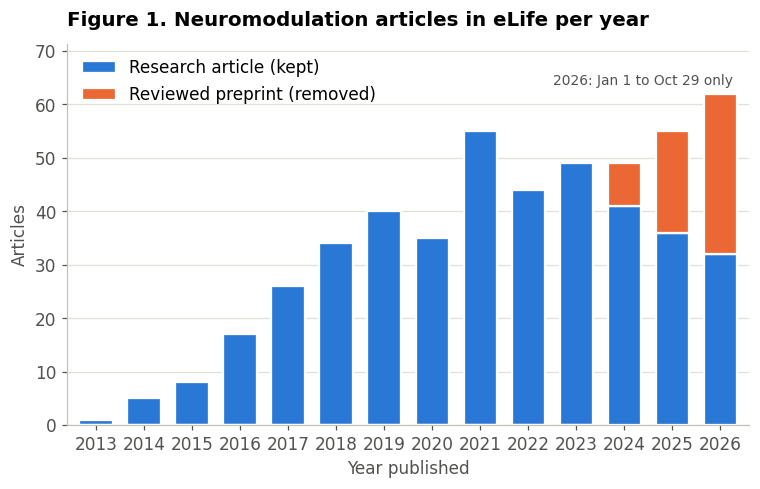

In [ ]:
per_year = pd.crosstab(articles["pub_year"], articles["type"])
fig, ax = plt.subplots()
per_year.plot.bar(stacked=True, ax=ax, color=[BLUE, ORANGE], width=0.7, edgecolor="white", linewidth=1.5, rot=0)
ax.grid(axis="x", visible=False)
ax.set(title="Figure 1. Neuromodulation articles in eLife per year", xlabel="Year published", ylabel="Articles")
ax.legend(["Research article (kept)", "Reviewed preprint (removed)"], loc="upper left")
ax.set_ylim(0, per_year.sum(axis=1).max() * 1.15)
ax.annotate("2026: Jan 1 to Oct 29 only", xy=(len(per_year) - 1, per_year.iloc[-1].sum()),
            xytext=(8, 6), textcoords="offset points", ha="right", fontsize=9, color="#52514e")
plt.show()

Research articles (blue) rose from 1 in 2013 to 55 in 2021 and stayed between 44 and 55 a year through 2023. After that they fall, to 32 so far in 2026, while reviewed preprints (orange) grow from 8 to 30. With both types counted, output keeps rising, and 2026 already has 62 matching papers with two months left. So the drop in research articles reflects how eLife now publishes papers, and interest in the topic has, if anything, grown. Because my final sample undercounts 2024 to 2026, I don't read trends from the blue bars after 2023.

### 4.3 Where the authors work

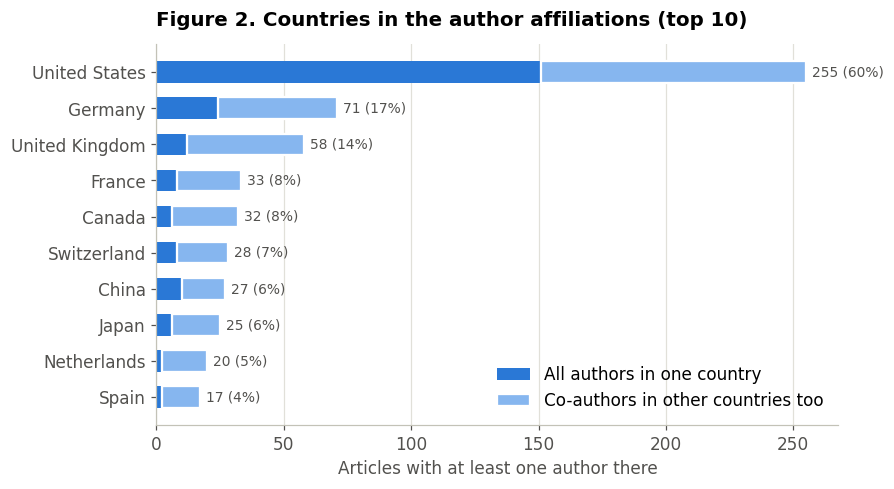

In [ ]:
by_country = (clean.assign(country=clean["countries"].str.split("; "), international=clean["n_countries"] > 1)
              .explode("country").groupby("country")["international"].agg(["size", "sum"]))
top = by_country.nlargest(10, "size").iloc[::-1]

fig, ax = plt.subplots()
ax.barh(top.index, top["size"] - top["sum"], color=BLUE, height=0.6, label="All authors in one country")
ax.barh(top.index, top["sum"], left=top["size"] - top["sum"], color=LIGHT_BLUE, height=0.6,
        edgecolor="white", linewidth=1.5, label="Co-authors in other countries too")
label_bars(ax, top["size"], len(clean))
ax.grid(axis="y", visible=False)
ax.set(title="Figure 2. Countries in the author affiliations (top 10)", xlabel="Articles with at least one author there")
ax.legend(loc="lower right")
plt.show()

60% of the articles have at least one author in the United States, far more than any other country. Germany (17%) and the United Kingdom (14%) follow, and the whole top ten is in North America, Europe and East Asia. Each bar is split by whether all of an article's authors are in that one country (dark blue) or some work elsewhere (light blue). In the US, 59% of articles have only US authors. In every other top-ten country, most articles are collaborations with other countries, from 63% for China to 90% for the Netherlands. Across the whole sample, 41% of articles have authors in more than one country.

### 4.4 Study organisms

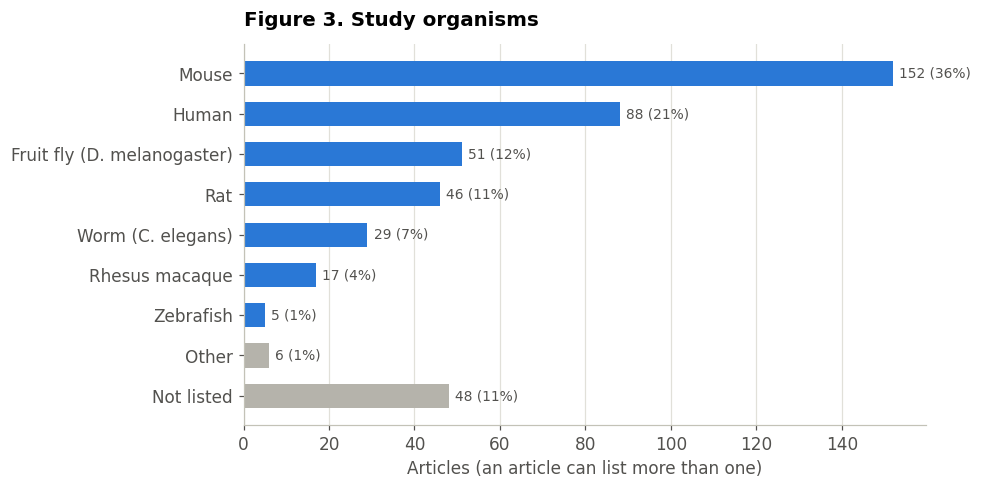

In [ ]:
organism_counts = clean["research_organisms"].str.split("; ").explode().value_counts()
not_listed = organism_counts.pop("Not listed")
organism_counts = pd.concat([organism_counts.head(7), pd.Series({"Other": organism_counts.iloc[7:].sum(),
                                                                 "Not listed": not_listed})]).iloc[::-1]
organism_counts = organism_counts.rename({"D. melanogaster": "Fruit fly (D. melanogaster)", "C. elegans": "Worm (C. elegans)"})
fig, ax = plt.subplots()
ax.barh(organism_counts.index, organism_counts.values, height=0.6,
        color=[GRAY if name in ("Other", "Not listed") else BLUE for name in organism_counts.index])
label_bars(ax, organism_counts.values, len(clean))
ax.grid(axis="y", visible=False)
ax.set(title="Figure 3. Study organisms", xlabel="Articles (an article can list more than one)")
plt.show()

Mice are the most common study animal, in 36% of the articles, followed by humans (21%), the fruit fly *D. melanogaster* (12%) and the rat (11%). The fly and the worm *C. elegans* together appear in 19% of the articles. Both have small nervous systems where researchers can follow single modulatory neurons, which may be why they show up so often in this work. 11% of the articles list no organism (Section 3.2). The percentages add up to more than 100 because 18 articles study more than one organism.

### 4.5 Which neuromodulators?

Articles that name none of these: 266 of 423


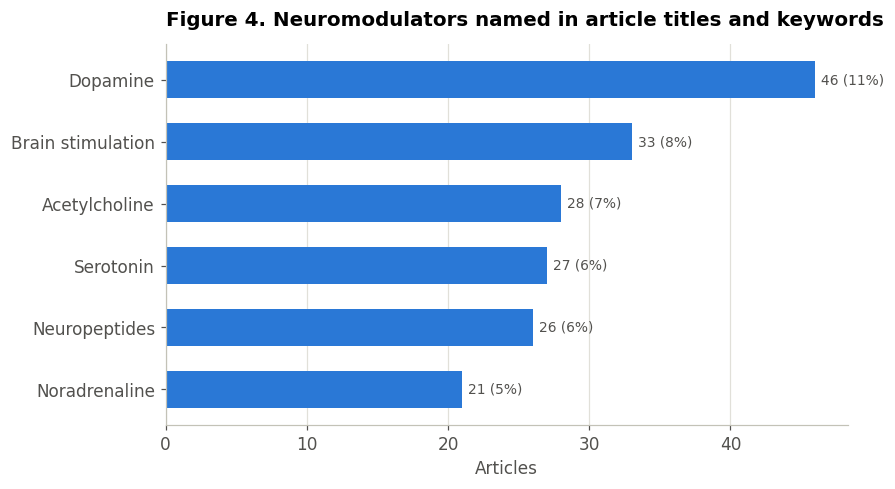

In [ ]:
patterns = {
    "Dopamine": r"dopamin",
    "Acetylcholine": r"acetylcholin|cholinergic|nicotinic|muscarinic",
    "Serotonin": r"serotonin|serotonergic|5-ht",
    "Noradrenaline": r"noradren|norepinephrin|locus coeruleus",
    "Neuropeptides": r"neuropeptide|peptidergic|oxytocin|vasopressin|orexin|hypocretin|somatostatin|tachykinin",
    "Brain stimulation": r"transcranial|brain stimulation|neurostimulation|ultrasound|vagus nerve stimulation"
                         r"|\btms\b|\btdcs\b|\btacs\b|\btrns\b",
}
text = (clean["title"] + " " + clean["keywords"]).str.lower()
named = pd.DataFrame({system: text.str.contains(pattern) for system, pattern in patterns.items()})
print(f"Articles that name none of these: {(~named.any(axis=1)).sum()} of {len(clean)}")

counts = named.sum().sort_values()
fig, ax = plt.subplots()
ax.barh(counts.index, counts.values, color=BLUE, height=0.6)
label_bars(ax, counts.values, len(clean))
ax.grid(axis="y", visible=False)
ax.set(title="Figure 4. Neuromodulators named in article titles and keywords", xlabel="Articles")
plt.show()

I counted an article under a neuromodulator if its title or keywords name it, for example "dopamine" or "dopaminergic". Dopamine leads with 46 articles. Acetylcholine (28), serotonin (27), neuropeptides (26) and noradrenaline (21) come after it, all at similar levels. The second-largest group, with 33 articles, is about brain stimulation, such as transcranial magnetic stimulation (TMS), direct current stimulation (tDCS), deep brain stimulation or focused ultrasound. "Neuromodulation" means both things in neuroscience, and the eLife search returns both. 266 articles (63%) name none of these in their title or keywords. eLife matches the search term anywhere in the full text, so many of these articles probably only touch on neuromodulation.

### 4.6 Team size and reference age over time

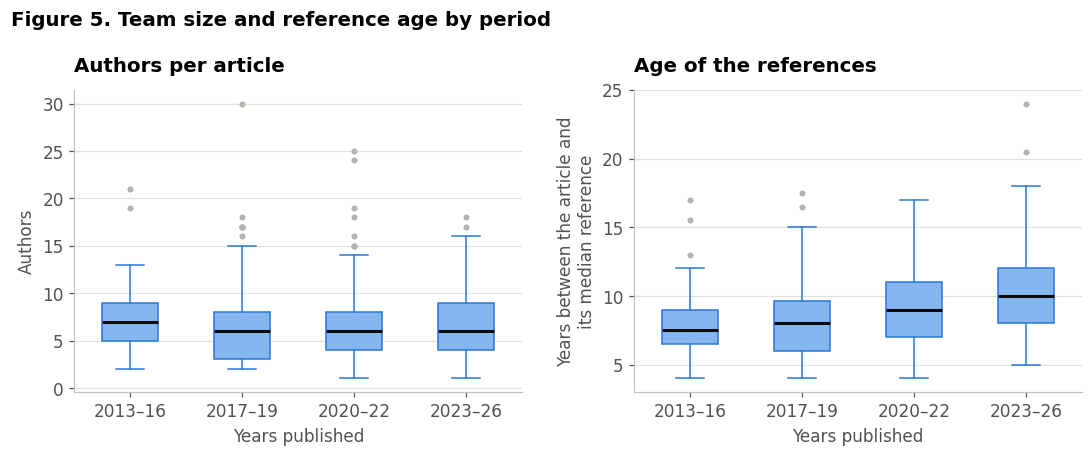

Years published,Articles,Median authors,Median reference age (years)
2013–16,31,7.0,7.5
2017–19,100,6.0,8.0
2020–22,134,6.0,9.0
2023–26,158,6.0,10.0


In [ ]:
clean["period"] = pd.cut(clean["pub_year"], [2012, 2016, 2019, 2022, 2026],
                         labels=["2013–16", "2017–19", "2020–22", "2023–26"])
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, column, title, ylabel in [(axes[0], "n_authors", "Authors per article", "Authors"),
                                  (axes[1], "reference_age", "Age of the references",
                                   "Years between the article and\nits median reference")]:
    groups = [group[column] for _, group in clean.groupby("period", observed=True)]
    ax.boxplot(groups, tick_labels=clean["period"].cat.categories, widths=0.5, patch_artist=True,
               boxprops={"facecolor": LIGHT_BLUE, "edgecolor": BLUE}, medianprops={"color": "#0b0b0b", "linewidth": 2},
               whiskerprops={"color": BLUE}, capprops={"color": BLUE},
               flierprops={"marker": "o", "markersize": 4, "markerfacecolor": GRAY, "markeredgecolor": "none"})
    ax.set(title=title, ylabel=ylabel, xlabel="Years published")
    ax.grid(axis="x", visible=False)
fig.suptitle("Figure 5. Team size and reference age by period", x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
plt.show()

show(clean.groupby("period", observed=True).agg(articles=("article_id", "size"), authors=("n_authors", "median"),
                                                ref_age=("reference_age", "median"))
     .set_axis(["Articles", "Median authors", "Median reference age (years)"], axis=1)
     .rename_axis(index=None, columns="Years published"),
     "Table 11. The medians behind Figure 5", precision=1, formats={"Articles": "{:,.0f}"})

Team size has barely moved. The median article had 7 authors in 2013–16 and 6 in every period since. The references have gotten steadily older. The median reference was 7.5 years old in 2013–16, 8 in 2017–19, 9 in 2020–22 and 10 in 2023–26. One possible reason is that the field has built up a larger body of past work, so new papers have more older studies to cite.

## 5. Discussion

Neuromodulation is a growing topic in eLife. Once reviewed preprints are counted, 2026 already has more papers than any earlier year. Most of the articles have US-based authors, and research outside the US is mostly done by international teams. Most studies use mice or humans, and dopamine is the neuromodulator named most often. The second-largest group of articles is about brain stimulation rather than brain chemistry, because the word "neuromodulation" covers both. Team sizes have stayed the same while the work being cited has gotten older.

The data have limits. eLife matches the search term anywhere in an article, so the sample includes papers where neuromodulation is a side topic. This is probably why 63% of the articles do not name a specific system in their title or keywords. The neuromodulator counts only use titles and keywords and will miss systems that are named only in the abstract or the main text. Reviewed preprints have no author or reference data in the API, so 2024 to 2026 are undercounted. Finally, eLife is one journal, so these results describe eLife's authors and not the whole field.